In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd().parent

# Dataset paths
arabian_path = (
    PROJECT_ROOT / "data" / "processed" / "gfw"
    / "arabian_sea" / "gfw_clean.csv"
)

bengal_path = (
    PROJECT_ROOT / "data" / "processed" / "gfw"
    / "bay_of_bengal" / "gfw_clean.csv"
)

# Load datasets
arabian = pd.read_csv(arabian_path)
bengal = pd.read_csv(bengal_path)

print("Arabian Sea Dataset:", arabian.shape)
print("Bay of Bengal Dataset:", bengal.shape)

print("\nArabian Sea Columns:")
print(arabian.columns.tolist())

print("\nBay of Bengal Columns:")
print(bengal.columns.tolist())

Arabian Sea Dataset: (684285, 7)
Bay of Bengal Dataset: (255414, 7)

Arabian Sea Columns:
['date', 'flag', 'hours', 'lat', 'lon', 'vesselIDs', 'region']

Bay of Bengal Columns:
['date', 'flag', 'hours', 'lat', 'lon', 'vesselIDs', 'region']


In [2]:
print("ARABIAN SEA")
display(arabian.head())
print(arabian.info())

print("\nBAY OF BENGAL")
display(bengal.head())
print(bengal.info())

ARABIAN SEA


,date,flag,hours,lat,lon,vesselIDs,region
0,2019-01,LKA,11.944444,11.5,65.6,1,arabian_sea
1,2019-01,Unknown,0.208611,10.5,65.6,1,arabian_sea
2,2019-01,CHN,4.950000,0.9,50.5,1,arabian_sea
3,2019-01,CHN,82.665833,13.0,58.3,6,arabian_sea
4,2019-01,CHN,23.499167,16.3,60.6,2,arabian_sea


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 684285 entries, 0 to 684284
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   date       684285 non-null  object 
 1   flag       684285 non-null  object 
 2   hours      684285 non-null  float64
 3   lat        684285 non-null  float64
 4   lon        684285 non-null  float64
 5   vesselIDs  684285 non-null  int64  
 6   region     684285 non-null  object 
dtypes: float64(3), int64(1), object(3)
memory usage: 36.5+ MB
None

BAY OF BENGAL


,date,flag,hours,lat,lon,vesselIDs,region
0,2019-01,LKA,7.980833,7.0,79.1,2,bay_of_bengal
1,2019-01,LKA,7.189167,6.8,79.3,1,bay_of_bengal
2,2019-01,LKA,4.582500,4.2,79.0,1,bay_of_bengal
3,2019-01,LKA,0.551944,6.7,78.0,1,bay_of_bengal
4,2019-01,TWN,0.583889,3.8,84.4,1,bay_of_bengal


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255414 entries, 0 to 255413
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   date       255414 non-null  object 
 1   flag       255414 non-null  object 
 2   hours      255414 non-null  float64
 3   lat        255414 non-null  float64
 4   lon        255414 non-null  float64
 5   vesselIDs  255414 non-null  int64  
 6   region     255414 non-null  object 
dtypes: float64(3), int64(1), object(3)
memory usage: 13.6+ MB
None


In [3]:
datasets = {
    "Arabian Sea": arabian,
    "Bay of Bengal": bengal
}

for name, df in datasets.items():

    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")

    print("Dataset shape:", df.shape)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nDate coverage:")
    print("Start:", df["date"].min())
    print("End:", df["date"].max())
    print("Unique months:", df["date"].nunique())

    print("\nCoordinate ranges:")
    print("Latitude:", df["lat"].min(), "to", df["lat"].max())
    print("Longitude:", df["lon"].min(), "to", df["lon"].max())

    print("\nUnique vessel flags:", df["flag"].nunique())

    print("\nFishing hours statistics:")
    print(df["hours"].describe())


Arabian Sea
Dataset shape: (684285, 7)

Missing values:
date         0
flag         0
hours        0
lat          0
lon          0
vesselIDs    0
region       0
dtype: int64

Duplicate rows: 0

Date coverage:
Start: 2019-01
End: 2025-12
Unique months: 84

Coordinate ranges:
Latitude: 0.0 to 25.0
Longitude: 50.0 to 78.0

Unique vessel flags: 50

Fishing hours statistics:
count    684285.000000
mean         13.613866
std          30.803225
min           0.000833
25%           2.069722
50%           5.763611
75%          14.635778
max        2436.631389
Name: hours, dtype: float64

Bay of Bengal
Dataset shape: (255414, 7)

Missing values:
date         0
flag         0
hours        0
lat          0
lon          0
vesselIDs    0
region       0
dtype: int64

Duplicate rows: 0

Date coverage:
Start: 2019-01
End: 2025-12
Unique months: 84

Coordinate ranges:
Latitude: 0.0 to 22.4
Longitude: 78.0 to 100.0

Unique vessel flags: 92

Fishing hours statistics:
count    255414.000000
mean         2

In [4]:
for name, df in datasets.items():

    print(f"\n===== {name} =====")

    print("Records:", len(df))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    print("Months:", df["date"].nunique())
    print("Date range:", df["date"].min(), "to", df["date"].max())

    print("Latitude:", df["lat"].min(), "to", df["lat"].max())
    print("Longitude:", df["lon"].min(), "to", df["lon"].max())

    print("Unique flags:", df["flag"].nunique())

    print("\nFishing hours:")
    print(df["hours"].describe().round(2))


===== Arabian Sea =====
Records: 684285
Missing values: 0
Duplicate rows: 0
Months: 84
Date range: 2019-01 to 2025-12
Latitude: 0.0 to 25.0
Longitude: 50.0 to 78.0
Unique flags: 50

Fishing hours:
count    684285.00
mean         13.61
std          30.80
min           0.00
25%           2.07
50%           5.76
75%          14.64
max        2436.63
Name: hours, dtype: float64

===== Bay of Bengal =====
Records: 255414
Missing values: 0
Duplicate rows: 0
Months: 84
Date range: 2019-01 to 2025-12
Latitude: 0.0 to 22.4
Longitude: 78.0 to 100.0
Unique flags: 92

Fishing hours:
count    255414.00
mean         22.07
std          51.07
min           0.00
25%           2.29
50%           8.28
75%          21.37
max        1284.50
Name: hours, dtype: float64


In [5]:
print("BAY OF BENGAL")
print("Records:", len(bengal))
print("Unique flags:", bengal["flag"].nunique())
print("Mean hours:", bengal["hours"].mean())
print("Median hours:", bengal["hours"].median())
print("Maximum hours:", bengal["hours"].max())
print("Minimum hours:", bengal["hours"].min())
print("Standard deviation:", bengal["hours"].std())

BAY OF BENGAL
Records: 255414
Unique flags: 92
Mean hours: 22.07305145062312
Median hours: 8.283472222222223
Maximum hours: 1284.5036111111112
Minimum hours: 0.0019444444444444
Standard deviation: 51.06791077624135


In [6]:
# Convert YYYY-MM into datetime
arabian["date"] = pd.to_datetime(arabian["date"], format="%Y-%m")
bengal["date"] = pd.to_datetime(bengal["date"], format="%Y-%m")

# Add year and month columns
for df in [arabian, bengal]:
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

In [7]:
# Monthly aggregated fishing hours
arabian_monthly = (
    arabian.groupby("date")["hours"]
    .sum()
)

bengal_monthly = (
    bengal.groupby("date")["hours"]
    .sum()
)

# Combine into one DataFrame
monthly_activity = pd.DataFrame({
    "Arabian Sea": arabian_monthly,
    "Bay of Bengal": bengal_monthly
})

display(monthly_activity.head(10))

,Arabian Sea,Bay of Bengal
date,,
2019-01-01,74094.885556,4642.622500
2019-02-01,61164.303611,4834.572222
2019-03-01,67458.987778,8184.621389
2019-04-01,56452.232500,6557.041111
2019-05-01,54801.897500,4351.004167
2019-06-01,30633.620000,6403.373056
2019-07-01,18766.406389,11040.705278
2019-08-01,28383.295000,8010.440278
2019-09-01,32094.284444,4615.174722


In [8]:
# Average activity for each calendar month across 2019–2025

arabian_seasonal = arabian.groupby("month")["hours"].mean()
bengal_seasonal = bengal.groupby("month")["hours"].mean()

seasonal_activity = pd.DataFrame({
    "Arabian Sea": arabian_seasonal,
    "Bay of Bengal": bengal_seasonal
})

display(seasonal_activity.round(2))

,Arabian Sea,Bay of Bengal
month,,
1,13.68,20.00
2,13.28,19.27
3,13.66,21.33
4,12.81,19.92
5,10.20,25.50
6,6.07,23.82
7,7.54,22.84
8,18.66,25.08
9,16.25,24.67


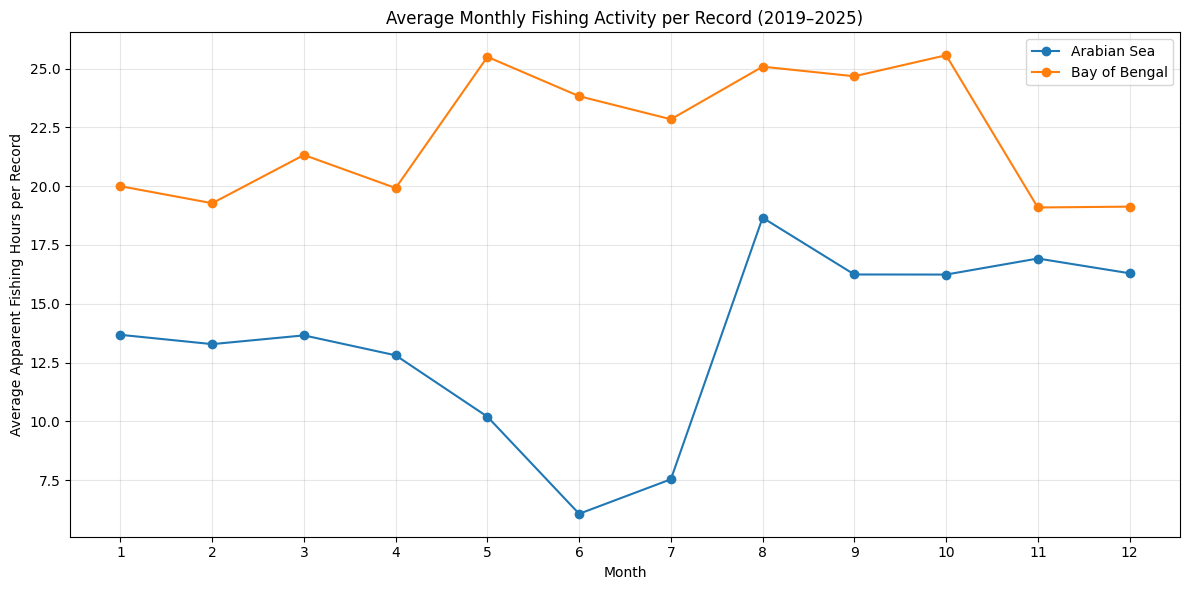

In [9]:
seasonal_activity.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Average Monthly Fishing Activity per Record (2019–2025)")
plt.xlabel("Month")
plt.ylabel("Average Apparent Fishing Hours per Record")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Calculate total apparent fishing hours for each year
arabian_yearly = arabian.groupby("year")["hours"].sum()
bengal_yearly = bengal.groupby("year")["hours"].sum()

# Combine both regions
yearly_activity = pd.DataFrame({
    "Arabian Sea": arabian_yearly,
    "Bay of Bengal": bengal_yearly
})

display(yearly_activity.round(2))

,Arabian Sea,Bay of Bengal
year,,
2019,589395.50,68474.83
2020,701067.88,98099.06
2021,806568.29,234338.86
2022,1839595.36,963031.81
2023,2102298.66,1314478.36
2024,1673034.38,1402813.96
2025,1603804.54,1556529.49


In [12]:
# Calculate year-over-year percentage change
yearly_change = yearly_activity.pct_change() * 100

display(yearly_change.round(2))

,Arabian Sea,Bay of Bengal
year,,
2019,NaN,NaN
2020,18.95,43.26
2021,15.05,138.88
2022,128.08,310.96
2023,14.28,36.49
2024,-20.42,6.72
2025,-4.14,10.96


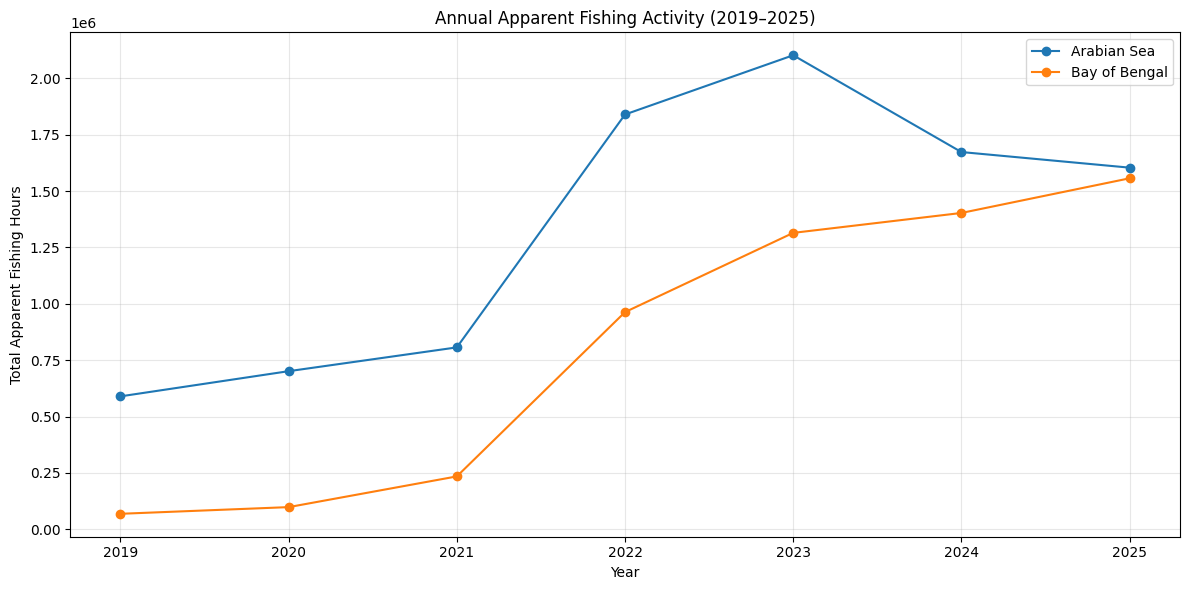

In [13]:
yearly_activity.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Annual Apparent Fishing Activity (2019–2025)")
plt.xlabel("Year")
plt.ylabel("Total Apparent Fishing Hours")
plt.xticks(range(2019, 2026))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


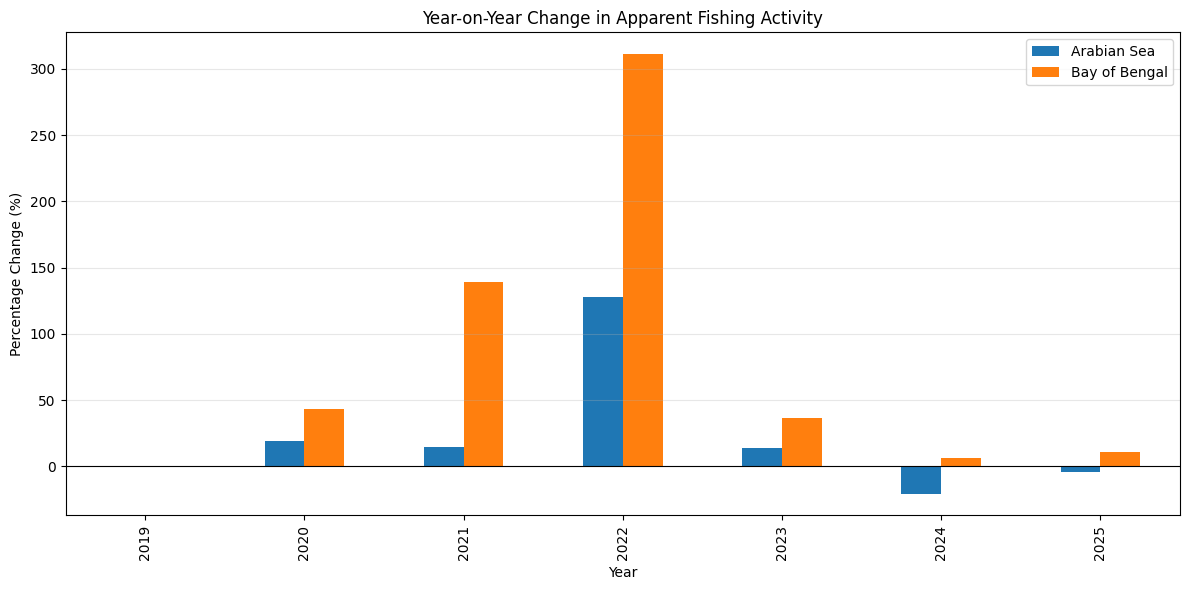

In [14]:
yearly_change.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Year-on-Year Change in Apparent Fishing Activity")
plt.xlabel("Year")
plt.ylabel("Percentage Change (%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# Aggregate fishing hours by spatial grid cell

arabian_spatial = (
    arabian.groupby(["lat", "lon"])["hours"]
    .sum()
    .reset_index()
)

bengal_spatial = (
    bengal.groupby(["lat", "lon"])["hours"]
    .sum()
    .reset_index()
)

print("Arabian Sea:")
display(arabian_spatial.describe())

print("Bay of Bengal:")
display(bengal_spatial.describe())

Arabian Sea:


,lat,lon,hours
count,48171.000000,48171.000000,48171.000000
mean,10.829474,63.064597,193.389479
std,6.549545,6.737996,480.893462
min,0.000000,50.000000,0.007500
25%,5.500000,58.000000,53.679415
50%,10.300000,63.000000,112.505194
75%,15.800000,67.900000,200.776897
max,25.000000,78.000000,22328.519389


Bay of Bengal:


,lat,lon,hours
count,21935.000000,21935.000000,21935.000000
mean,8.344509,86.526984,257.021489
std,5.624062,5.168809,1110.455282
min,0.000000,78.000000,0.015833
25%,3.600000,82.700000,17.024861
50%,7.100000,85.900000,54.207028
75%,13.100000,89.300000,157.656250
max,22.400000,100.000000,48140.068994


In [16]:
# Top 10 fishing activity grid cells

print("Top 10 Arabian Sea Hotspots:")
arabian_hotspots = arabian_spatial.nlargest(10, "hours")
display(arabian_hotspots)

print("Top 10 Bay of Bengal Hotspots:")
bengal_hotspots = bengal_spatial.nlargest(10, "hours")
display(bengal_hotspots)

Top 10 Arabian Sea Hotspots:


,lat,lon,hours
30222,12.9,74.6,22328.519389
29791,12.7,74.7,21106.707461
30008,12.8,74.6,19712.958411
30009,12.8,74.7,15945.237531
30439,13.0,74.6,14966.263691
29792,12.7,74.8,13288.755014
29575,12.6,74.7,13286.701557
30440,13.0,74.7,13169.009386
31330,13.4,73.6,12967.064128
30664,13.1,74.7,12932.355103


Top 10 Bay of Bengal Hotspots:


,lat,lon,hours
6294,4.1,99.9,48140.068994
6458,4.2,99.9,47087.571547
6612,4.3,99.9,45073.826128
6457,4.2,99.8,40724.432706
6611,4.3,99.8,35263.510119
6131,4.0,99.9,27164.416597
6769,4.4,99.8,24314.964019
6459,4.2,100.0,23880.594622
6770,4.4,99.9,22626.677833
6610,4.3,99.7,22217.915286


C:\Users\91911\AppData\Local\Temp\ipykernel_17336\1744235096.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


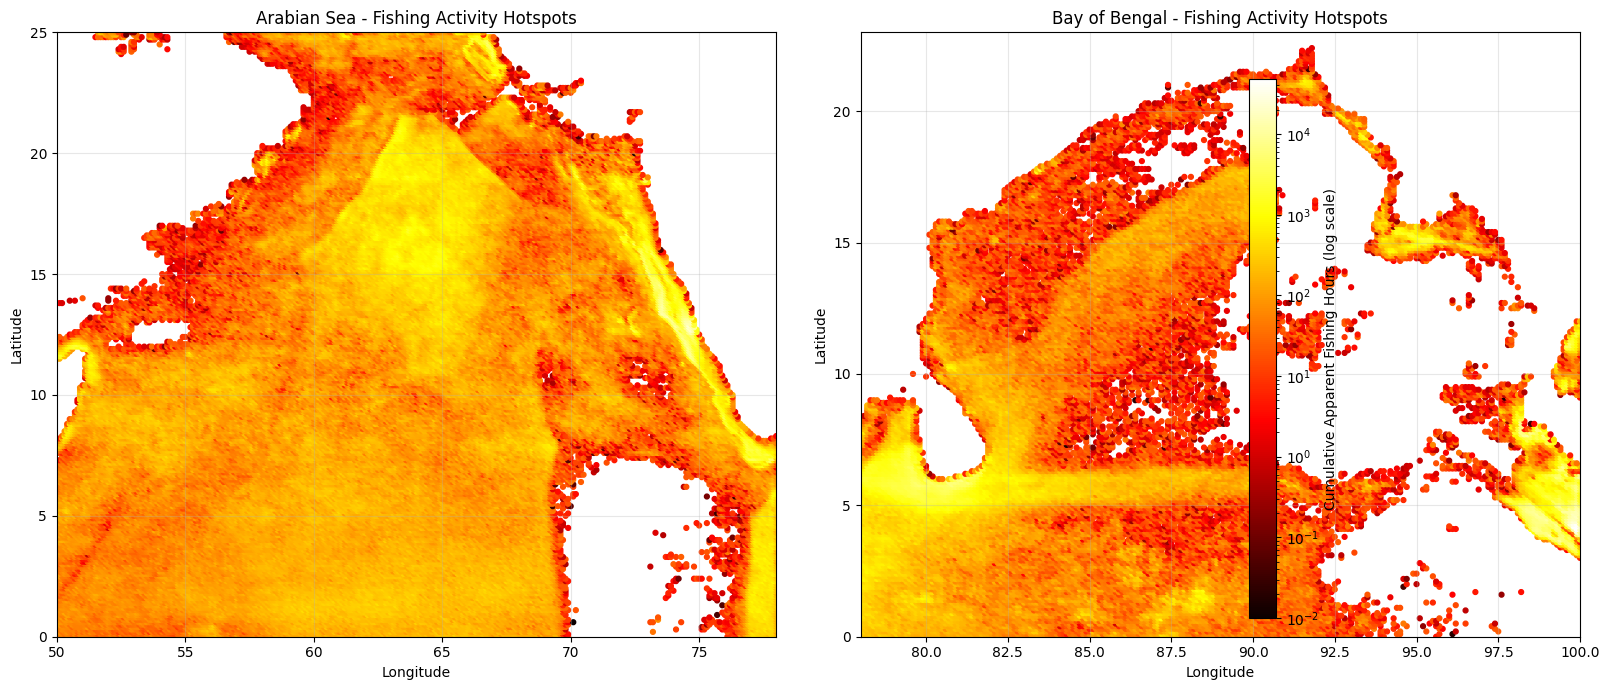

In [17]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Arabian Sea
sc1 = axes[0].scatter(
    arabian_spatial["lon"],
    arabian_spatial["lat"],
    c=arabian_spatial["hours"],
    cmap="hot",
    norm=LogNorm(vmin=0.01, vmax=48140.07),
    s=12
)

axes[0].set_title("Arabian Sea - Fishing Activity Hotspots")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_xlim(50, 78)
axes[0].set_ylim(0, 25)
axes[0].grid(alpha=0.3)

# Bay of Bengal
sc2 = axes[1].scatter(
    bengal_spatial["lon"],
    bengal_spatial["lat"],
    c=bengal_spatial["hours"],
    cmap="hot",
    norm=LogNorm(vmin=0.01, vmax=48140.07),
    s=12
)

axes[1].set_title("Bay of Bengal - Fishing Activity Hotspots")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_xlim(78, 100)
axes[1].set_ylim(0, 23)
axes[1].grid(alpha=0.3)

fig.colorbar(sc2, ax=axes, label="Cumulative Apparent Fishing Hours (log scale)")

plt.tight_layout()
plt.show()

In [18]:
# Investigate fishing activity near the eastern boundary
# of the Bay of Bengal region

boundary_cells = bengal_spatial[
    bengal_spatial["lon"] >= 99.5
]

print("Total grid cells:", len(bengal_spatial))
print("Grid cells near eastern boundary:", len(boundary_cells))

print(
    "Percentage of grid cells near boundary:",
    round(len(boundary_cells) / len(bengal_spatial) * 100, 2),
    "%"
)

total_hours = bengal_spatial["hours"].sum()
boundary_hours = boundary_cells["hours"].sum()

print("Total apparent fishing hours:", round(total_hours, 2))
print("Boundary apparent fishing hours:", round(boundary_hours, 2))

print(
    "Percentage of total activity near boundary:",
    round(boundary_hours / total_hours * 100, 2),
    "%"
)

Total grid cells: 21935
Grid cells near eastern boundary: 357
Percentage of grid cells near boundary: 1.63 %
Total apparent fishing hours: 5637766.36
Boundary apparent fishing hours: 1192882.08
Percentage of total activity near boundary: 21.16 %


In [19]:
# Divide longitude into 2-degree bands

bengal_spatial["lon_band"] = (
    (bengal_spatial["lon"] // 2) * 2
)

longitude_activity = (
    bengal_spatial.groupby("lon_band")
    .agg(
        grid_cells=("hours", "count"),
        total_hours=("hours", "sum"),
        average_hours=("hours", "mean")
    )
    .reset_index()
)

longitude_activity["activity_percentage"] = (
    longitude_activity["total_hours"]
    / longitude_activity["total_hours"].sum()
) * 100

display(longitude_activity.round(2))

,lon_band,grid_cells,total_hours,average_hours,activity_percentage
0,78.0,1769,1107516.99,626.07,19.64
1,80.0,2537,846090.94,333.50,15.01
2,82.0,3370,416642.51,123.63,7.39
3,84.0,3405,227746.09,66.89,4.04
4,86.0,3267,218067.51,66.75,3.87
5,88.0,2820,194731.36,69.05,3.45
6,90.0,1811,92173.34,50.90,1.63
7,92.0,781,39194.61,50.19,0.70
8,94.0,482,121789.72,252.68,2.16
9,96.0,671,40773.71,60.77,0.72


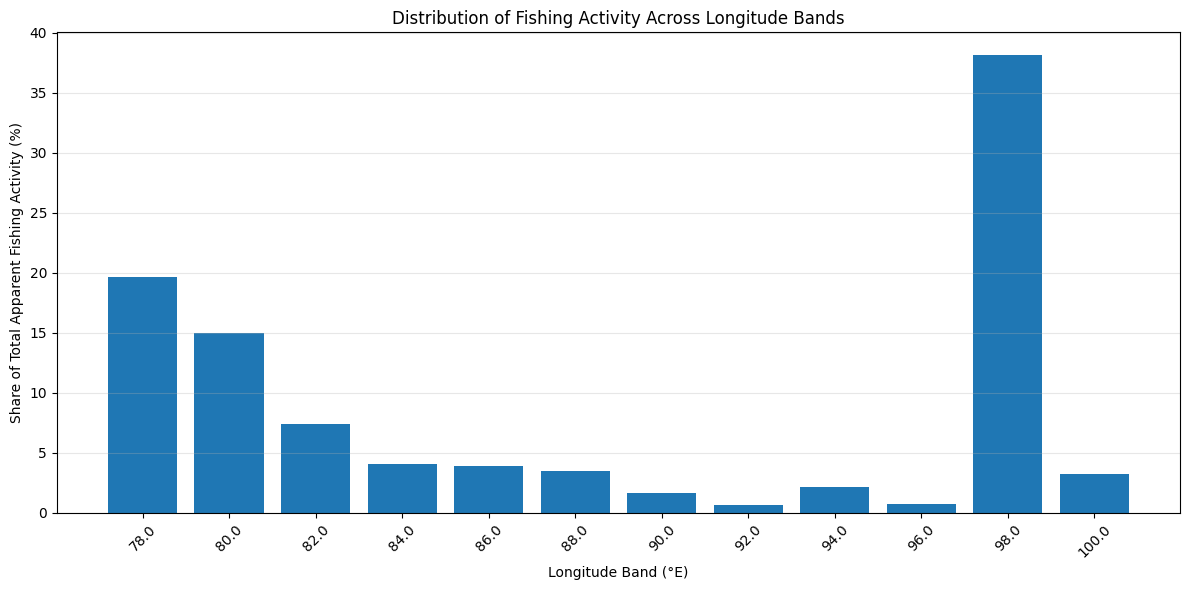

In [20]:
plt.figure(figsize=(12, 6))

plt.bar(
    longitude_activity["lon_band"].astype(str),
    longitude_activity["activity_percentage"]
)

plt.title("Distribution of Fishing Activity Across Longitude Bands")
plt.xlabel("Longitude Band (°E)")
plt.ylabel("Share of Total Apparent Fishing Activity (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
print("Maximum longitude:", bengal_spatial["lon"].max())

display(
    bengal_spatial[bengal_spatial["lon"] >= 100]
    .sort_values("lon", ascending=False)
    .head(20)
)

Maximum longitude: 100.0


,lat,lon,hours,lon_band
4639,3.0,100.0,5.869722,100.0
4785,3.1,100.0,195.210075,100.0
4928,3.2,100.0,866.352922,100.0
5074,3.3,100.0,1015.752083,100.0
5222,3.4,100.0,288.261217,100.0
5372,3.5,100.0,159.174608,100.0
5522,3.6,100.0,4.910556,100.0
5675,3.7,100.0,445.930689,100.0
5828,3.8,100.0,279.240436,100.0
5978,3.9,100.0,9828.506839,100.0


In [22]:
(bengal_spatial["lon"] // 2) * 2

0        78.0
1        78.0
2        78.0
3        78.0
4        78.0
         ... 
21930    90.0
21931    90.0
21932    90.0
21933    90.0
21934    90.0
Name: lon, Length: 21935, dtype: float64

In [23]:
# Assign the eastern boundary (100° E) to the 98°–100° band
bengal_spatial["lon_band"] = (
    (bengal_spatial["lon"] // 2) * 2
).clip(upper=98)

# Recalculate longitude-wise activity
longitude_activity = (
    bengal_spatial.groupby("lon_band")
    .agg(
        grid_cells=("hours", "count"),
        total_hours=("hours", "sum"),
        average_hours=("hours", "mean")
    )
    .reset_index()
)

longitude_activity["activity_percentage"] = (
    longitude_activity["total_hours"]
    / longitude_activity["total_hours"].sum()
) * 100

display(longitude_activity.round(2))

,lon_band,grid_cells,total_hours,average_hours,activity_percentage
0,78.0,1769,1107516.99,626.07,19.64
1,80.0,2537,846090.94,333.50,15.01
2,82.0,3370,416642.51,123.63,7.39
3,84.0,3405,227746.09,66.89,4.04
4,86.0,3267,218067.51,66.75,3.87
5,88.0,2820,194731.36,69.05,3.45
6,90.0,1811,92173.34,50.90,1.63
7,92.0,781,39194.61,50.19,0.70
8,94.0,482,121789.72,252.68,2.16
9,96.0,671,40773.71,60.77,0.72


In [24]:
# Check the corrected longitude-band assignments
print("Unique longitude bands:")
print(sorted(bengal_spatial["lon_band"].unique()))

print("\nMaximum longitude:")
print(bengal_spatial["lon"].max())

Unique longitude bands:
[np.float64(78.0), np.float64(80.0), np.float64(82.0), np.float64(84.0), np.float64(86.0), np.float64(88.0), np.float64(90.0), np.float64(92.0), np.float64(94.0), np.float64(96.0), np.float64(98.0)]

Maximum longitude:
100.0


In [25]:
display(longitude_activity.round(2))

,lon_band,grid_cells,total_hours,average_hours,activity_percentage
0,78.0,1769,1107516.99,626.07,19.64
1,80.0,2537,846090.94,333.50,15.01
2,82.0,3370,416642.51,123.63,7.39
3,84.0,3405,227746.09,66.89,4.04
4,86.0,3267,218067.51,66.75,3.87
5,88.0,2820,194731.36,69.05,3.45
6,90.0,1811,92173.34,50.90,1.63
7,92.0,781,39194.61,50.19,0.70
8,94.0,482,121789.72,252.68,2.16
9,96.0,671,40773.71,60.77,0.72


In [26]:
# Aggregate fishing hours by flag

arabian_flag = (
    arabian.groupby("flag")["hours"]
    .sum()
    .sort_values(ascending=False)
)

bengal_flag = (
    bengal.groupby("flag")["hours"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 flags - Arabian Sea")
display(arabian_flag.head(10))

print("Top 10 flags - Bay of Bengal")
display(bengal_flag.head(10))

Top 10 flags - Arabian Sea


flag
IND        2.753503e+06
CHN        2.241102e+06
IRN        1.717727e+06
LKA        1.347309e+06
TWN        5.020319e+05
PAK        2.647898e+05
Unknown    2.287596e+05
SYC        1.283959e+05
OMN        4.568128e+04
MUS        1.875916e+04
Name: hours, dtype: float64

Top 10 flags - Bay of Bengal


flag
LKA        2.533608e+06
MYS        1.025369e+06
IDN        9.487433e+05
THA        3.347259e+05
Unknown    2.420733e+05
IND        1.211209e+05
MMR        9.608602e+04
CHN        8.318005e+04
TWN        7.941219e+04
SYC        1.908157e+04
Name: hours, dtype: float64

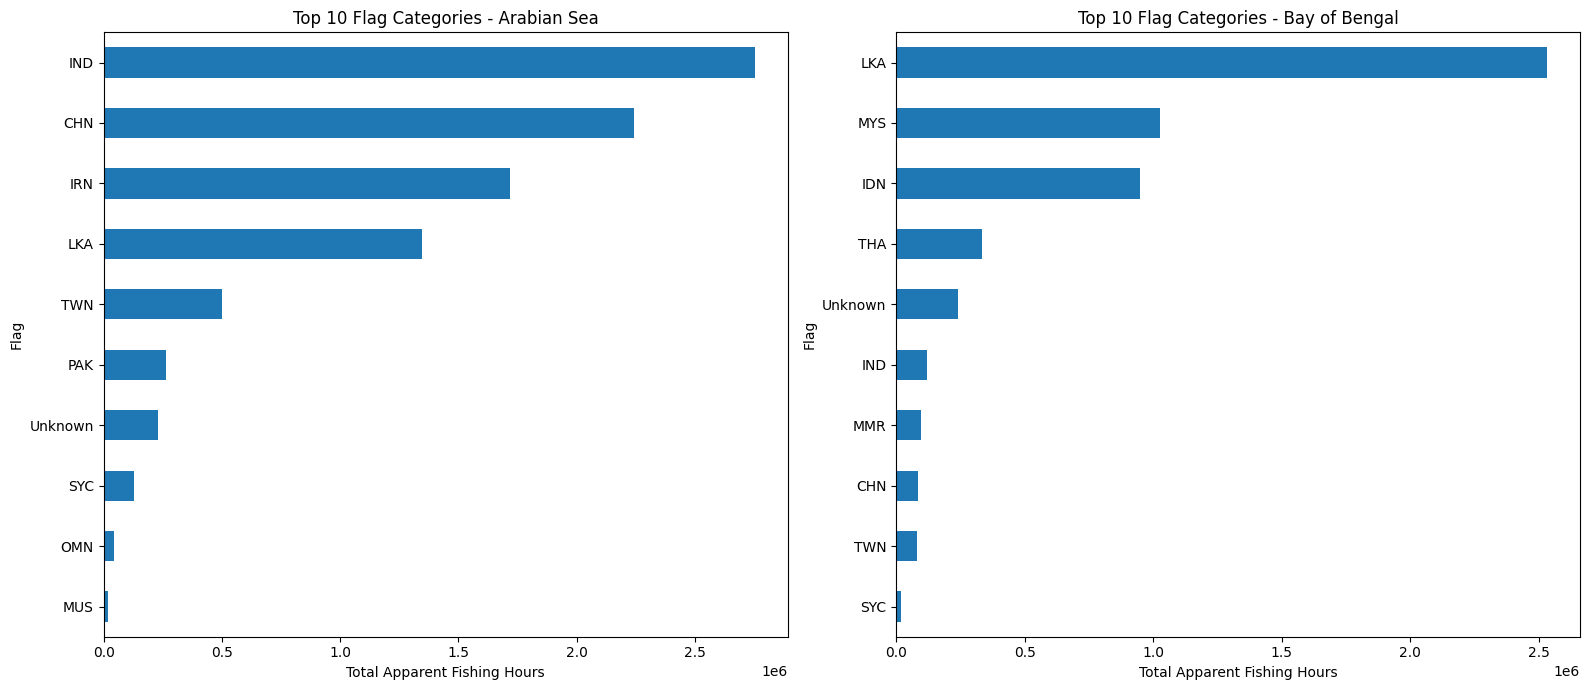

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Arabian Sea
arabian_flag.head(10).sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("Top 10 Flag Categories - Arabian Sea")
axes[0].set_xlabel("Total Apparent Fishing Hours")
axes[0].set_ylabel("Flag")

# Bay of Bengal
bengal_flag.head(10).sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("Top 10 Flag Categories - Bay of Bengal")
axes[1].set_xlabel("Total Apparent Fishing Hours")
axes[1].set_ylabel("Flag")

plt.tight_layout()
plt.show()

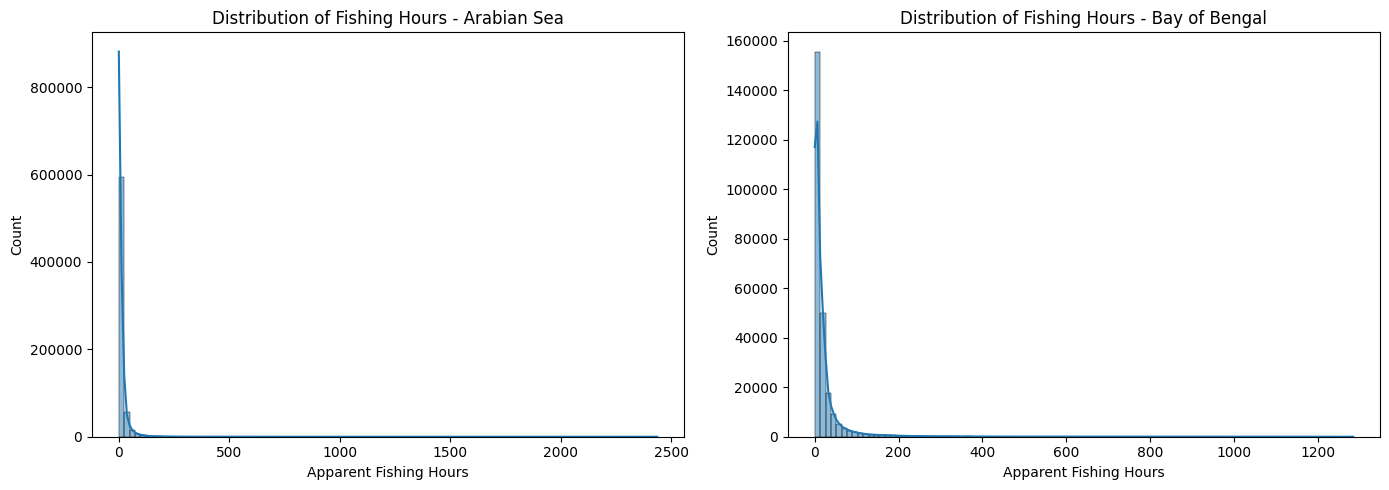

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Arabian Sea
sns.histplot(
    arabian["hours"],
    bins=100,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Fishing Hours - Arabian Sea")
axes[0].set_xlabel("Apparent Fishing Hours")

# Bay of Bengal
sns.histplot(
    bengal["hours"],
    bins=100,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Fishing Hours - Bay of Bengal")
axes[1].set_xlabel("Apparent Fishing Hours")

plt.tight_layout()
plt.show()

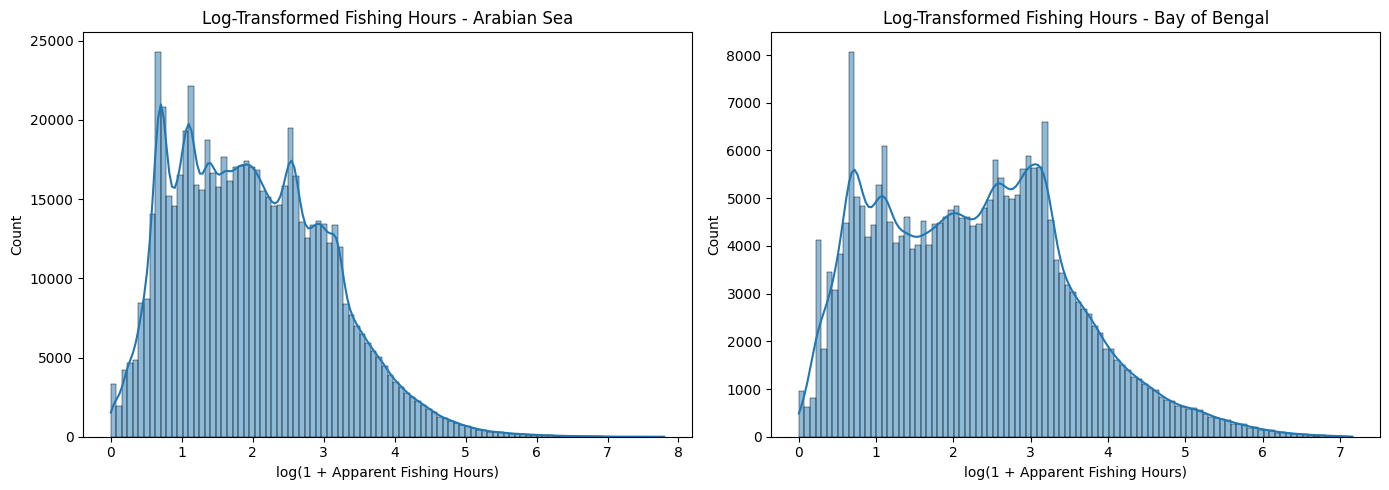

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    np.log1p(arabian["hours"]),
    bins=100,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Log-Transformed Fishing Hours - Arabian Sea")
axes[0].set_xlabel("log(1 + Apparent Fishing Hours)")

sns.histplot(
    np.log1p(bengal["hours"]),
    bins=100,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Log-Transformed Fishing Hours - Bay of Bengal")
axes[1].set_xlabel("log(1 + Apparent Fishing Hours)")

plt.tight_layout()
plt.show()

In [30]:
# Calculate percentiles for both regions

percentiles = [50, 90, 95, 99, 99.9]

for name, df in {
    "Arabian Sea": arabian,
    "Bay of Bengal": bengal
}.items():

    print(f"\n{name}")

    values = df["hours"].quantile(
        [p / 100 for p in percentiles]
    )

    for p, value in zip(percentiles, values):
        print(f"{p}th percentile: {value:.2f} hours")


Arabian Sea
50th percentile: 5.76 hours
90th percentile: 29.63 hours
95th percentile: 47.43 hours
99th percentile: 119.20 hours
99.9th percentile: 392.10 hours

Bay of Bengal
50th percentile: 8.28 hours
90th percentile: 46.75 hours
95th percentile: 83.20 hours
99th percentile: 245.80 hours
99.9th percentile: 627.96 hours


In [31]:
for name, df in {
    "Arabian Sea": arabian,
    "Bay of Bengal": bengal
}.items():

    print(f"\n{name}")

    total_hours = df["hours"].sum()

    for percentile in [95, 99]:
        threshold = df["hours"].quantile(percentile / 100)

        extreme_records = df[df["hours"] >= threshold]

        record_percentage = (
            len(extreme_records) / len(df)
        ) * 100

        activity_percentage = (
            extreme_records["hours"].sum() / total_hours
        ) * 100

        print(f"\nRecords at or above {percentile}th percentile:")
        print(f"Threshold: {threshold:.2f} hours")
        print(f"Number of records: {len(extreme_records)}")
        print(f"Percentage of records: {record_percentage:.2f}%")
        print(f"Share of total activity: {activity_percentage:.2f}%")


Arabian Sea

Records at or above 95th percentile:
Threshold: 47.43 hours
Number of records: 34215
Percentage of records: 5.00%
Share of total activity: 37.28%

Records at or above 99th percentile:
Threshold: 119.20 hours
Number of records: 6843
Percentage of records: 1.00%
Share of total activity: 16.69%

Bay of Bengal

Records at or above 95th percentile:
Threshold: 83.20 hours
Number of records: 12771
Percentage of records: 5.00%
Share of total activity: 42.71%

Records at or above 99th percentile:
Threshold: 245.80 hours
Number of records: 2555
Percentage of records: 1.00%
Share of total activity: 18.14%


In [32]:
columns = ["date", "flag", "lat", "lon", "hours", "vesselIDs"]

print("Top 20 extreme records - Arabian Sea")
display(
    arabian.nlargest(20, "hours")[columns]
)

print("\nTop 20 extreme records - Bay of Bengal")
display(
    bengal.nlargest(20, "hours")[columns]
)

Top 20 extreme records - Arabian Sea


,date,flag,lat,lon,hours,vesselIDs
560761,2024-09-01,IND,13.4,73.6,2436.631389,148
654409,2025-08-01,IND,13.9,73.8,1874.914722,86
559561,2024-09-01,IND,13.5,73.6,1818.873056,121
654943,2025-08-01,IND,12.8,74.6,1461.544167,163
657520,2025-09-01,IND,12.7,74.2,1452.264167,135
311900,2022-10-01,IND,12.0,74.6,1451.985747,107
345800,2023-01-01,IND,7.4,77.8,1423.780833,70
434504,2023-08-01,IND,12.8,74.6,1377.881389,147
348084,2023-02-01,IND,7.4,77.8,1351.601667,100
654837,2025-08-01,IND,13.8,73.8,1322.159167,87



Top 20 extreme records - Bay of Bengal


,date,flag,lat,lon,hours,vesselIDs
169110,2024-06-01,MYS,4.1,99.9,1284.503611,43
203674,2025-01-01,MYS,4.3,99.9,1262.595000,48
204971,2025-02-01,MYS,4.3,99.9,1221.548333,48
228498,2025-07-01,MYS,4.1,99.9,1183.529722,47
146405,2024-01-01,IDN,4.6,98.9,1159.560278,41
195811,2024-12-01,MYS,4.1,99.9,1155.964167,49
169633,2024-06-01,MYS,4.2,99.9,1145.912222,54
172345,2024-06-01,MYS,4.2,99.8,1143.368611,41
71061,2022-09-01,MYS,4.3,99.9,1141.238808,49
215780,2025-03-01,LKA,6.1,81.6,1132.381111,65


In [33]:
columns = ["date", "flag", "lat", "lon", "hours", "vesselIDs"]

display(
    arabian.nlargest(20, "hours")[columns]
)


,date,flag,lat,lon,hours,vesselIDs
560761,2024-09-01,IND,13.4,73.6,2436.631389,148
654409,2025-08-01,IND,13.9,73.8,1874.914722,86
559561,2024-09-01,IND,13.5,73.6,1818.873056,121
654943,2025-08-01,IND,12.8,74.6,1461.544167,163
657520,2025-09-01,IND,12.7,74.2,1452.264167,135
311900,2022-10-01,IND,12.0,74.6,1451.985747,107
345800,2023-01-01,IND,7.4,77.8,1423.780833,70
434504,2023-08-01,IND,12.8,74.6,1377.881389,147
348084,2023-02-01,IND,7.4,77.8,1351.601667,100
654837,2025-08-01,IND,13.8,73.8,1322.159167,87


In [34]:
# Divide latitude into 2-degree bands

bengal_spatial["lat_band"] = (
    (bengal_spatial["lat"] // 2) * 2
)

latitude_activity = (
    bengal_spatial.groupby("lat_band")
    .agg(
        grid_cells=("hours", "count"),
        total_hours=("hours", "sum"),
        average_hours=("hours", "mean")
    )
    .reset_index()
)

latitude_activity["activity_percentage"] = (
    latitude_activity["total_hours"]
    / latitude_activity["total_hours"].sum()
) * 100

display(latitude_activity.round(2))

,lat_band,grid_cells,total_hours,average_hours,activity_percentage
0,0.0,3076,368601.14,119.83,6.54
1,2.0,2903,523357.57,180.28,9.28
2,4.0,3412,2857672.72,837.54,50.69
3,6.0,2315,1055996.28,456.15,18.73
4,8.0,1721,207144.14,120.36,3.67
5,10.0,1960,161885.22,82.59,2.87
6,12.0,1790,74797.40,41.79,1.33
7,14.0,2358,248789.06,105.51,4.41
8,16.0,1356,93972.71,69.30,1.67
9,18.0,599,24428.06,40.78,0.43


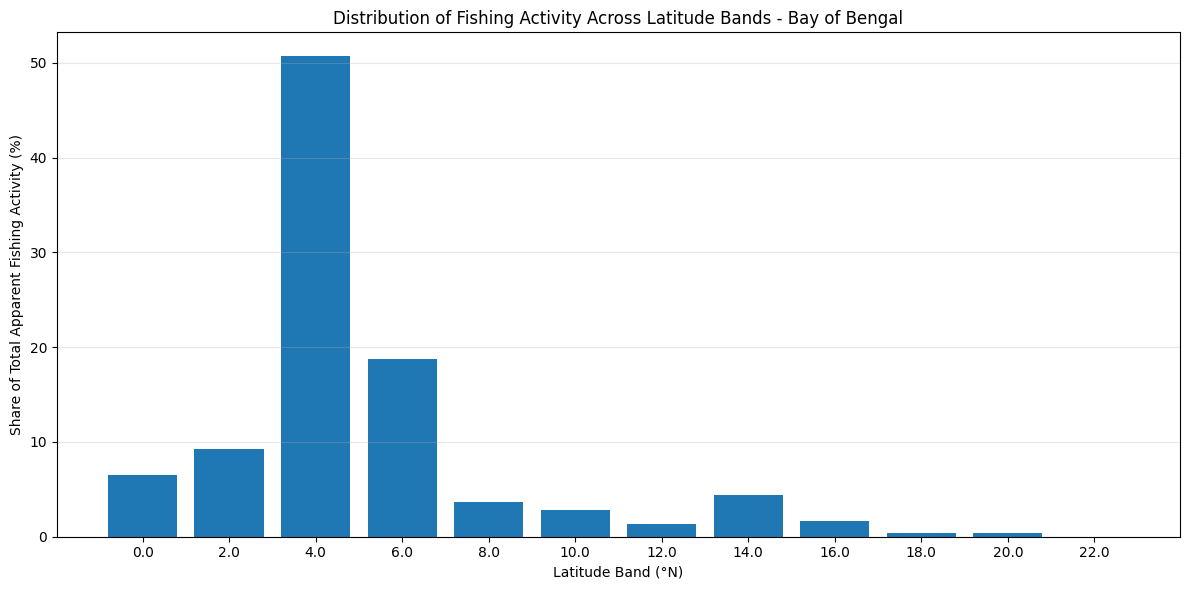

In [35]:
plt.figure(figsize=(12, 6))

plt.bar(
    latitude_activity["lat_band"].astype(str),
    latitude_activity["activity_percentage"]
)

plt.title("Distribution of Fishing Activity Across Latitude Bands - Bay of Bengal")
plt.xlabel("Latitude Band (°N)")
plt.ylabel("Share of Total Apparent Fishing Activity (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# Divide Arabian Sea into 2-degree latitude bands

arabian_spatial["lat_band"] = (
    (arabian_spatial["lat"] // 2) * 2
)

arabian_latitude_activity = (
    arabian_spatial.groupby("lat_band")
    .agg(
        grid_cells=("hours", "count"),
        total_hours=("hours", "sum"),
        average_hours=("hours", "mean")
    )
    .reset_index()
)

arabian_latitude_activity["activity_percentage"] = (
    arabian_latitude_activity["total_hours"]
    / arabian_latitude_activity["total_hours"].sum()
) * 100

display(arabian_latitude_activity.round(2))

,lat_band,grid_cells,total_hours,average_hours,activity_percentage
0,0.0,4396,710664.96,161.66,7.63
1,2.0,4359,680337.71,156.08,7.30
2,4.0,4311,550585.61,127.72,5.91
3,6.0,4890,689931.77,141.09,7.41
4,8.0,5226,787810.50,150.75,8.46
5,10.0,4815,783001.35,162.62,8.41
6,12.0,4457,1524778.43,342.11,16.37
7,14.0,3944,1153538.88,292.48,12.38
8,16.0,3642,985711.02,270.65,10.58
9,18.0,3073,777897.43,253.14,8.35


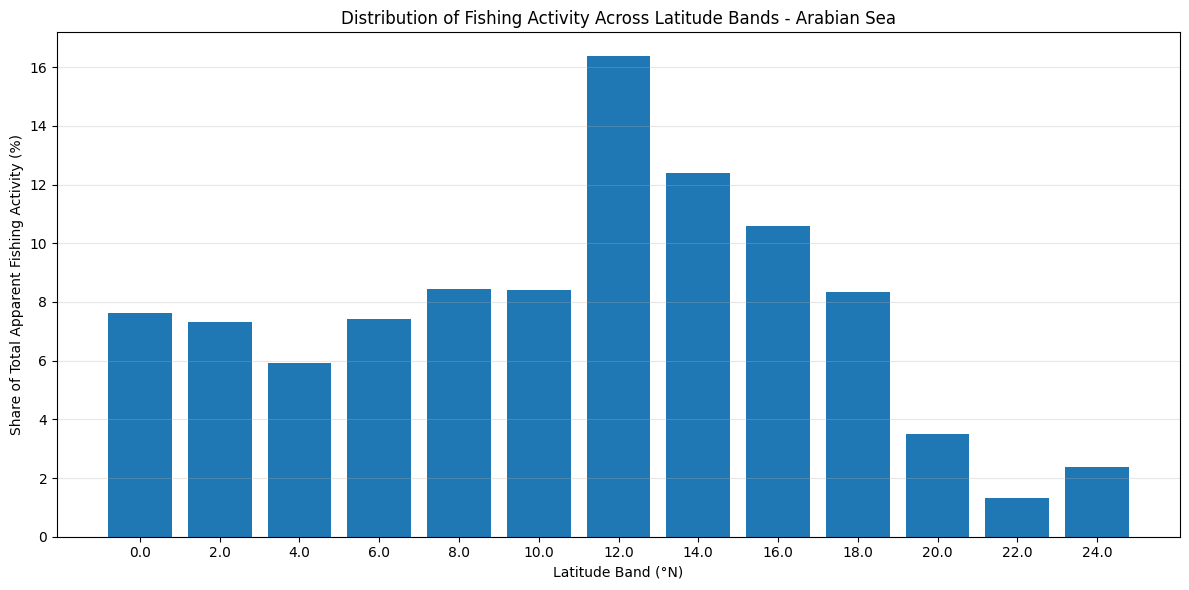

In [37]:
plt.figure(figsize=(12, 6))

plt.bar(
    arabian_latitude_activity["lat_band"].astype(str),
    arabian_latitude_activity["activity_percentage"]
)

plt.title("Distribution of Fishing Activity Across Latitude Bands - Arabian Sea")
plt.xlabel("Latitude Band (°N)")
plt.ylabel("Share of Total Apparent Fishing Activity (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()